In [1]:
import json
import time
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid")

CWD = Path.cwd()
BASE_DIR = CWD.parent if CWD.name == "analysis" else CWD
RESULT_DIR = BASE_DIR / "results"
FIG_DIR = RESULT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chronological boundaries
TRAIN_START, TRAIN_END = "2025-02-08", "2025-11-26"
VAL_START, VAL_END     = "2025-11-27", "2026-01-01"
TEST_START, TEST_END   = "2026-01-02", "2026-02-07"

REQUIRED_ARTIFACTS = [
    RESULT_DIR / "fact_delay.parquet",
    RESULT_DIR / "dim_train.csv",
    RESULT_DIR / "dim_station.csv",
    RESULT_DIR / "dim_date.csv",
    RESULT_DIR / "step04_01_train_period_station_stats.parquet",
    RESULT_DIR / "step04_01_train_period_transition_stats.parquet",
    RESULT_DIR / "step04_01_NETWORK_FINDINGS.json",
]
for fp in REQUIRED_ARTIFACTS:
    assert fp.exists(), f"Missing required input artifact: {fp}"

con = duckdb.connect(database=":memory:")
con.execute("PRAGMA threads=4;")

fact_cols = [
    r[0] for r in con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{(RESULT_DIR / 'fact_delay.parquet').as_posix()}')"
    ).fetchall()
]
DATE_COL = "date_id" if "date_id" in fact_cols else "date"

con.execute(f"""
CREATE OR REPLACE VIEW fact_delay AS
SELECT
    CAST({DATE_COL} AS DATE) AS date_id,
    * EXCLUDE ({DATE_COL})
FROM read_parquet('{(RESULT_DIR / "fact_delay.parquet").as_posix()}');

CREATE OR REPLACE VIEW dim_train AS
SELECT * FROM read_csv_auto('{(RESULT_DIR / "dim_train.csv").as_posix()}');

CREATE OR REPLACE VIEW train_station_stats AS
SELECT * FROM read_parquet('{(RESULT_DIR / "step04_01_train_period_station_stats.parquet").as_posix()}');

CREATE OR REPLACE VIEW train_transition_stats AS
SELECT * FROM read_parquet('{(RESULT_DIR / "step04_01_train_period_transition_stats.parquet").as_posix()}');
""")

print("Connected to read-only views over fact_delay.parquet and Step 4.1 training-period network Parquets.")

Connected to read-only views over fact_delay.parquet and Step 4.1 training-period network Parquets.


In [2]:
# Compute global training-period baseline priors & train-category delay priors strictly on Training dates
t0 = time.time()

global_train_priors = con.execute(f"""
WITH train_transitions AS (
    SELECT
        date_id,
        train_no,
        sched_station_no AS curr_sched_no,
        delay AS curr_delay,
        is_imputed AS curr_imp,
        LEAD(sched_station_no) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS next_sched_no,
        LEAD(delay) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS next_delay,
        LEAD(is_imputed) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS next_imp,
        LEAD(inter_station_distance) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS seg_dist_km,
        LEAD(scheduled_arrival_min) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no)
          - scheduled_departure_min AS seg_run_min
    FROM fact_delay
    WHERE date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
      AND has_schedule = TRUE
)
SELECT
    COUNT(*) AS n_train_transitions,
    ROUND(AVG(next_delay), 6) AS global_train_arr_mean_delay,
    ROUND(MEDIAN(next_delay), 6) AS global_train_arr_median_delay,
    ROUND(AVG(next_delay - curr_delay), 6) AS global_train_delta_mean,
    ROUND(MEDIAN(next_delay - curr_delay), 6) AS global_train_delta_median,
    ROUND(MEDIAN(GREATEST(seg_dist_km, 0.0)), 6) AS median_train_seg_dist_km,
    ROUND(MEDIAN(GREATEST(seg_run_min, 1.0)), 6) AS median_train_seg_run_min
FROM train_transitions
WHERE next_sched_no = curr_sched_no + 1
  AND curr_imp = FALSE
  AND next_imp = FALSE;
""").df()

GLOBAL_ARR_MEAN   = float(global_train_priors["global_train_arr_mean_delay"].iloc[0])
GLOBAL_DELTA_MEAN = float(global_train_priors["global_train_delta_mean"].iloc[0])
MEDIAN_SEG_DIST   = float(global_train_priors["median_train_seg_dist_km"].iloc[0])
MEDIAN_SEG_RUN    = float(global_train_priors["median_train_seg_run_min"].iloc[0])
SHRINKAGE_M       = 50.0

print("=== TRAINING-ONLY GLOBAL PRIORS (2025-02-08 TO 2025-11-26) ===")
print(global_train_priors.to_string(index=False))

# Fit training-only train-category (primary_type_code, is_premium_special) arrival delay priors with m=50 shrinkage
train_cat_priors_df = con.execute(f"""
WITH train_arr AS (
    SELECT
        f.train_no,
        dt.primary_type_code,
        dt.is_premium_special,
        f.delay
    FROM fact_delay f
    JOIN dim_train dt ON f.train_no = dt.train_no
    WHERE f.date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
      AND f.has_schedule = TRUE
      AND f.is_imputed = FALSE
      AND f.station_no > 1
)
SELECT
    primary_type_code,
    is_premium_special,
    COUNT(*) AS train_obs_arrival_count,
    ROUND(AVG(delay), 4) AS raw_cat_mean_delay_min,
    ROUND(
        (COUNT(*) * AVG(delay) + {SHRINKAGE_M} * {GLOBAL_ARR_MEAN})
        / (COUNT(*) + {SHRINKAGE_M}),
        4
    ) AS train_category_delay_prior_min
FROM train_arr
GROUP BY primary_type_code, is_premium_special
ORDER BY train_obs_arrival_count DESC;
""").df()

con.register("vw_train_cat_priors", train_cat_priors_df)
print("\n=== TRAINING-ONLY SERVICE CATEGORY DELAY PRIORS ===")
print(train_cat_priors_df.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== TRAINING-ONLY GLOBAL PRIORS (2025-02-08 TO 2025-11-26) ===
 n_train_transitions  global_train_arr_mean_delay  global_train_arr_median_delay  global_train_delta_mean  global_train_delta_median  median_train_seg_dist_km  median_train_seg_run_min
            26528080                    35.371894                           16.0                 0.852798                        0.0                       9.0                      12.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


=== TRAINING-ONLY SERVICE CATEGORY DELAY PRIORS ===
primary_type_code  is_premium_special  train_obs_arrival_count  raw_cat_mean_delay_min  train_category_delay_prior_min
      PASS-TRAINS               False                 13136448                 32.7654                         32.7654
       EXP-TRAINS               False                  9537448                 35.9700                         35.9700
        SF-TRAINS               False                  3526474                 42.7523                         42.7522
       T18-TRAINS                True                   210363                 13.8704                         13.8755
       PRM-TRAINS                True                   108464                 92.6853                         92.6589
       RAJ-TRAINS               False                    80053                 26.8459                         26.8512
       GRB-TRAINS               False                    68815                 50.7826                         50.

In [3]:
# Audit total scheduled transitions vs. eligible observed transitions across all three chronological splits
transition_eligibility_audit = con.execute(f"""
WITH all_sched_pairs AS (
    SELECT
        date_id,
        train_no,
        sched_station_no AS curr_sched_no,
        is_imputed AS curr_imp,
        LEAD(sched_station_no) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS next_sched_no,
        LEAD(is_imputed) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS next_imp
    FROM fact_delay
    WHERE has_schedule = TRUE
)
SELECT
    CASE
        WHEN date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}' THEN '1_Train (2025-02-08 to 2025-11-26)'
        WHEN date_id BETWEEN DATE '{VAL_START}'   AND DATE '{VAL_END}'   THEN '2_Validation (2025-11-27 to 2026-01-01)'
        WHEN date_id BETWEEN DATE '{TEST_START}'  AND DATE '{TEST_END}'  THEN '3_Test (2026-01-02 to 2026-02-07)'
    END AS split_name,
    COUNT(*) FILTER (WHERE next_sched_no IS NOT NULL) AS total_consecutive_rows_in_journey,
    COUNT(*) FILTER (WHERE next_sched_no = curr_sched_no + 1) AS contiguous_sched_transitions,
    COUNT(*) FILTER (WHERE next_sched_no = curr_sched_no + 1 AND NOT curr_imp AND NOT next_imp) AS eligible_obs_transitions,
    COUNT(*) FILTER (WHERE next_sched_no = curr_sched_no + 1 AND (curr_imp OR next_imp)) AS excluded_imputed_transitions,
    COUNT(*) FILTER (WHERE next_sched_no IS NOT NULL AND next_sched_no != curr_sched_no + 1) AS skipped_non_contiguous_stops
FROM all_sched_pairs
GROUP BY 1
ORDER BY 1;
""").df()

print("=== TRANSITION ELIGIBILITY & CONTINUITY AUDIT ACROSS CHRONOLOGICAL SPLITS ===")
print(transition_eligibility_audit.to_string(index=False))

# Define the 12 core predictive features
FEATURE_COLS = [
    "curr_delay_min",
    "prev_delay_min",
    "prev_delay_delta_min",
    "train_category_delay_prior_min",
    "route_progress_ratio",
    "is_terminal_arrival",
    "segment_distance_km",
    "segment_sched_running_min",
    "next_sched_arrival_hour",
    "next_station_betweenness",
    "next_station_hist_arr_delay_min",
    "transition_hist_delay_delta_min",
]
TARGET_COL = "target_next_delay_min"

def build_partition_query(start_date: str, end_date: str) -> str:
    return f"""
    WITH journey_seq AS (
        SELECT
            f.date_id,
            f.train_no,
            f.station_no AS curr_delay_station_no,
            f.sched_station_no AS curr_sched_station_no,
            f.station_name AS curr_station_name,
            f.delay AS curr_delay_min,
            f.is_imputed AS curr_is_imputed,
            f.scheduled_departure_min AS curr_sched_dep_min,
            MAX(f.sched_station_no) OVER (PARTITION BY f.date_id, f.train_no) AS max_sched_station_no,
            -- Previous stop (k-1) information available at prediction time
            LAG(f.sched_station_no) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS prev_sched_station_no,
            LAG(f.delay) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS raw_prev_delay_min,
            LAG(f.is_imputed) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS prev_is_imputed,
            -- Next stop (k+1) target & static schedule attributes known at prediction time
            LEAD(f.station_no) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS next_delay_station_no,
            LEAD(f.sched_station_no) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS next_sched_station_no,
            LEAD(f.station_name) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS next_station_name,
            LEAD(f.delay) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS target_next_delay_min,
            LEAD(f.is_imputed) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS next_is_imputed,
            LEAD(f.severity) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS target_severity,
            LEAD(f.inter_station_distance) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS raw_seg_dist_km,
            LEAD(f.scheduled_arrival_min) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS next_sched_arr_min,
            LEAD(f.arrival_time) OVER (PARTITION BY f.date_id, f.train_no ORDER BY f.sched_station_no) AS next_arrival_time_str
        FROM fact_delay f
        WHERE f.date_id BETWEEN DATE '{start_date}' AND DATE '{end_date}'
          AND f.has_schedule = TRUE
    ),
    eligible_pairs AS (
        SELECT
            js.*,
            CASE
                WHEN js.prev_sched_station_no = js.curr_sched_station_no - 1
                 AND js.prev_is_imputed = FALSE
                 AND js.raw_prev_delay_min IS NOT NULL
                THEN js.raw_prev_delay_min
                ELSE js.curr_delay_min
            END AS clean_prev_delay_min
        FROM journey_seq js
        WHERE js.next_sched_station_no = js.curr_sched_station_no + 1
          AND js.curr_is_imputed = FALSE
          AND js.next_is_imputed = FALSE
          AND js.curr_station_name != js.next_station_name
    )
    SELECT
        -- Identifiers & Post-Prediction Stratified Evaluation Metadata (excluded from feature matrix X)
        ep.date_id,
        CAST(ep.train_no AS INTEGER) AS train_no,
        CAST(ep.curr_sched_station_no AS SMALLINT) AS curr_sched_station_no,
        CAST(ep.next_sched_station_no AS SMALLINT) AS next_sched_station_no,
        ep.curr_station_name,
        ep.next_station_name,
        dt.primary_type_code,
        dt.is_premium_special,
        ep.target_severity,
        -- Target Variable (y)
        CAST(ep.target_next_delay_min AS FLOAT) AS target_next_delay_min,
        -- 12 Leakage-Free Predictive Features (X) stored as FLOAT32 for memory efficiency
        CAST(ep.curr_delay_min AS FLOAT) AS curr_delay_min,
        CAST(ep.clean_prev_delay_min AS FLOAT) AS prev_delay_min,
        CAST(ep.curr_delay_min - ep.clean_prev_delay_min AS FLOAT) AS prev_delay_delta_min,
        CAST(COALESCE(tcp.train_category_delay_prior_min, {GLOBAL_ARR_MEAN}) AS FLOAT) AS train_category_delay_prior_min,
        CAST(CAST(ep.next_sched_station_no AS DOUBLE) / CAST(GREATEST(ep.max_sched_station_no, 2) AS DOUBLE) AS FLOAT) AS route_progress_ratio,
        CAST(CASE WHEN ep.next_sched_station_no = ep.max_sched_station_no THEN 1.0 ELSE 0.0 END AS FLOAT) AS is_terminal_arrival,
        CAST(COALESCE(GREATEST(ep.raw_seg_dist_km, 0.0), ts_edge.median_sched_segment_dist_km, {MEDIAN_SEG_DIST}) AS FLOAT) AS segment_distance_km,
        CAST(COALESCE(GREATEST(ep.next_sched_arr_min - ep.curr_sched_dep_min, 1.0), ts_edge.median_sched_running_min, {MEDIAN_SEG_RUN}) AS FLOAT) AS segment_sched_running_min,
        CAST(COALESCE(TRY_CAST(SPLIT_PART(CAST(ep.next_arrival_time_str AS VARCHAR), ':', 1) AS INTEGER), CAST( FLOOR((ep.next_sched_arr_min % 1440) / 60) AS INTEGER ), 12) AS FLOAT) AS next_sched_arrival_hour,
        CAST(COALESCE(ts_node.betweenness_centrality, 0.0) AS FLOAT) AS next_station_betweenness,
        CAST(
            COALESCE(
                (ts_node.train_obs_arrival_stops * ts_node.train_arr_mean_delay_min + {SHRINKAGE_M} * {GLOBAL_ARR_MEAN})
                / NULLIF(ts_node.train_obs_arrival_stops + {SHRINKAGE_M}, 0),
                {GLOBAL_ARR_MEAN}
            ) AS FLOAT
        ) AS next_station_hist_arr_delay_min,
        CAST(
            COALESCE(
                (ts_edge.train_obs_transition_count * ts_edge.train_mean_delay_delta_min + {SHRINKAGE_M} * {GLOBAL_DELTA_MEAN})
                / NULLIF(ts_edge.train_obs_transition_count + {SHRINKAGE_M}, 0),
                {GLOBAL_DELTA_MEAN}
            ) AS FLOAT
        ) AS transition_hist_delay_delta_min
    FROM eligible_pairs ep
    LEFT JOIN dim_train dt
      ON ep.train_no = dt.train_no
    LEFT JOIN vw_train_cat_priors tcp
      ON dt.primary_type_code = tcp.primary_type_code
     AND dt.is_premium_special = tcp.is_premium_special
    LEFT JOIN train_station_stats ts_node
      ON ep.next_station_name = ts_node.station_name
    LEFT JOIN train_transition_stats ts_edge
      ON ep.curr_station_name = ts_edge.from_station
     AND ep.next_station_name = ts_edge.to_station
    """

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== TRANSITION ELIGIBILITY & CONTINUITY AUDIT ACROSS CHRONOLOGICAL SPLITS ===
                             split_name  total_consecutive_rows_in_journey  contiguous_sched_transitions  eligible_obs_transitions  excluded_imputed_transitions  skipped_non_contiguous_stops
     1_Train (2025-02-08 to 2025-11-26)                           27200874                      27171229                  26528080                        643149                         29645
2_Validation (2025-11-27 to 2026-01-01)                            3320092                       3316870                   3278765                         38105                          3222
      3_Test (2026-01-02 to 2026-02-07)                            3388116                       3384737                   3351989                         32748                          3379


In [4]:
t_export = time.time()

train_parquet_path = RESULT_DIR / "step04_02_train_features.parquet"
val_parquet_path   = RESULT_DIR / "step04_02_val_features.parquet"
test_parquet_path  = RESULT_DIR / "step04_02_test_features.parquet"

for split_label, s_date, e_date, out_path in [
    ("Train",      TRAIN_START, TRAIN_END, train_parquet_path),
    ("Validation", VAL_START,   VAL_END,   val_parquet_path),
    ("Test",       TEST_START,  TEST_END,  test_parquet_path),
]:
    t_s = time.time()
    q_sql = build_partition_query(s_date, e_date)
    con.execute(f"COPY ({q_sql}) TO '{out_path.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD);")
    size_mb = out_path.stat().st_size / (1024 * 1024)
    n_rows = con.execute(f"SELECT COUNT(*) FROM read_parquet('{out_path.as_posix()}')").fetchone()[0]
    print(f"Materialized {split_label:10s} ({s_date} to {e_date}): {n_rows:11,d} rows | {size_mb:6.2f} MB in {time.time() - t_s:.2f}s")

print(f"\nAll three chronological prediction datasets exported in {time.time() - t_export:.2f}s.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Materialized Train      (2025-02-08 to 2025-11-26):  26,528,080 rows | 397.22 MB in 49.77s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Materialized Validation (2025-11-27 to 2026-01-01):   3,278,765 rows |  49.13 MB in 7.16s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Materialized Test       (2026-01-02 to 2026-02-07):   3,351,989 rows |  49.85 MB in 5.65s

All three chronological prediction datasets exported in 62.57s.


In [5]:
# Fit z-score standardization parameters (mean, std, median, IQR, min, max, Pearson r with target) strictly on Training Parquet
feature_stats_rows = []
for feat in FEATURE_COLS:
    stats_row = con.execute(f"""
    SELECT
        '{feat}' AS feature_name,
        COUNT(*) AS train_n,
        SUM(CASE WHEN {feat} IS NULL OR ISNAN({feat}) OR NOT ISFINITE({feat}) THEN 1 ELSE 0 END) AS train_null_or_inf,
        ROUND(AVG(CAST({feat} AS DOUBLE)), 6) AS train_mean,
        ROUND(STDDEV_SAMP(CAST({feat} AS DOUBLE)), 6) AS train_std,
        ROUND(MIN(CAST({feat} AS DOUBLE)), 6) AS train_min,
        ROUND(QUANTILE_CONT(CAST({feat} AS DOUBLE), 0.25), 6) AS train_p25,
        ROUND(MEDIAN(CAST({feat} AS DOUBLE)), 6) AS train_median,
        ROUND(QUANTILE_CONT(CAST({feat} AS DOUBLE), 0.75), 6) AS train_p75,
        ROUND(MAX(CAST({feat} AS DOUBLE)), 6) AS train_max,
        ROUND(CORR(CAST({feat} AS DOUBLE), CAST({TARGET_COL} AS DOUBLE)), 4) AS corr_with_target_train
    FROM read_parquet('{train_parquet_path.as_posix()}');
    """).df().iloc[0].to_dict()
    feature_stats_rows.append(stats_row)

feature_metadata_df = pd.DataFrame(feature_stats_rows)
print("=== ENGINEERED FEATURE SUMMARY & TRAINING-SET PREPROCESSING PARAMETERS (12 FEATURES) ===")
print(feature_metadata_df.to_string(index=False))

assert int(feature_metadata_df["train_null_or_inf"].sum()) == 0, "Null or infinite values detected in training features!"
assert all(feature_metadata_df["train_std"] > 0), "Zero-variance feature detected!"

# Audit all 3 partitions for date boundaries, duplicate keys, missing values, and target distributions
null_check_expr = " + ".join([f"SUM(CASE WHEN {c} IS NULL OR ISNAN({c}) THEN 1 ELSE 0 END)" for c in FEATURE_COLS + [TARGET_COL]])

split_summary_rows = []
for split_name, p_path, exp_start, exp_end in [
    ("1_Train",      train_parquet_path, TRAIN_START, TRAIN_END),
    ("2_Validation", val_parquet_path,   VAL_START,   VAL_END),
    ("3_Test",       test_parquet_path,  TEST_START,  TEST_END),
]:
    row_df = con.execute(f"""
    SELECT
        '{split_name}' AS partition_name,
        CAST(MIN(date_id) AS VARCHAR) AS min_date,
        CAST(MAX(date_id) AS VARCHAR) AS max_date,
        COUNT(DISTINCT date_id) AS n_days,
        COUNT(*) AS n_transitions,
        COUNT(DISTINCT train_no) AS n_trains,
        COUNT(DISTINCT next_station_name) AS n_target_stations,
        COUNT(*) - COUNT(DISTINCT (date_id, train_no, curr_sched_station_no, next_sched_station_no)) AS duplicate_transition_keys,
        ({null_check_expr}) AS total_nulls_across_features_and_target,
        ROUND(AVG(target_next_delay_min), 4) AS target_mean_delay_min,
        ROUND(MEDIAN(target_next_delay_min), 4) AS target_median_delay_min,
        ROUND(STDDEV_SAMP(target_next_delay_min), 4) AS target_std_delay_min,
        ROUND(QUANTILE_CONT(target_next_delay_min, 0.90), 4) AS target_p90_delay_min,
        ROUND(AVG(CASE WHEN target_next_delay_min <= 15 THEN 100.0 ELSE 0.0 END), 2) AS target_on_time_15m_pct,
        ROUND(AVG(CASE WHEN target_severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END), 4) AS target_bottleneck_gt_2sd_pct
    FROM read_parquet('{p_path.as_posix()}');
    """).df()
    assert row_df["min_date"].iloc[0] == exp_start and row_df["max_date"].iloc[0] == exp_end, f"Date boundary mismatch in {split_name}!"
    assert int(row_df["duplicate_transition_keys"].iloc[0]) == 0, f"Duplicate keys in {split_name}!"
    assert int(row_df["total_nulls_across_features_and_target"].iloc[0]) == 0, f"Null values found in {split_name}!"
    split_summary_rows.append(row_df.iloc[0].to_dict())

split_summary_df = pd.DataFrame(split_summary_rows)
split_summary_df["pct_of_prediction_dataset"] = (
    split_summary_df["n_transitions"] * 100.0 / split_summary_df["n_transitions"].sum()
).round(4)

print("\n=== VALIDATED CHRONOLOGICAL SPLIT SUMMARY (TRAIN / VALIDATION / TEST) ===")
print(split_summary_df.to_string(index=False))

# Save metadata CSVs & preprocessing artifacts JSON
feature_metadata_df.to_csv(RESULT_DIR / "step04_02_feature_engineering_metadata.csv", index=False)
split_summary_df.to_csv(RESULT_DIR / "step04_02_split_and_feature_metadata.csv", index=False)

preprocessing_artifacts = {
    "target_column": TARGET_COL,
    "feature_columns": FEATURE_COLS,
    "metadata_columns": [
        "date_id", "train_no", "curr_sched_station_no", "next_sched_station_no",
        "curr_station_name", "next_station_name", "primary_type_code", "is_premium_special", "target_severity"
    ],
    "chronological_splits": {
        "train": [TRAIN_START, TRAIN_END],
        "validation": [VAL_START, VAL_END],
        "test": [TEST_START, TEST_END],
    },
    "shrinkage_smoothing_m": SHRINKAGE_M,
    "global_train_priors": global_train_priors.to_dict(orient="records")[0],
    "train_category_priors": train_cat_priors_df.to_dict(orient="records"),
    "standard_scaler_fit_on_train": {
        row["feature_name"]: {
            "mean": float(row["train_mean"]),
            "std": float(row["train_std"]),
            "median": float(row["train_median"]),
        }
        for row in feature_stats_rows
    },
}

with open(RESULT_DIR / "step04_02_preprocessing_artifacts.json", "w", encoding="utf-8") as f:
    json.dump(preprocessing_artifacts, f, indent=2)
print("Saved training-fitted scaler and priors to results/step04_02_preprocessing_artifacts.json")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (5 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== ENGINEERED FEATURE SUMMARY & TRAINING-SET PREPROCESSING PARAMETERS (12 FEATURES) ===
                   feature_name  train_n  train_null_or_inf  train_mean  train_std    train_min  train_p25  train_median  train_p75   train_max  corr_with_target_train
                 curr_delay_min 26528080                0.0   34.519096  62.677551   -57.000000   4.000000     16.000000  39.000000 1440.000000                  0.9600
                 prev_delay_min 26528080                0.0   32.961334  61.249649   -57.000000   3.000000     14.000000  37.000000 1440.000000                  0.9377
           prev_delay_delta_min 26528080                0.0    1.557762  15.932256 -1440.000000  -1.000000      0.000000   3.000000 1436.000000                  0.1717
 train_category_delay_prior_min 26528080                0.0   35.359905   6.076811     9.978400  32.765400     32.765400  35.970001   96.584900                  0.0946
           route_progress_ratio 26528080                0.0    0.550170

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


=== VALIDATED CHRONOLOGICAL SPLIT SUMMARY (TRAIN / VALIDATION / TEST) ===
partition_name   min_date   max_date  n_days  n_transitions  n_trains  n_target_stations  duplicate_transition_keys  total_nulls_across_features_and_target  target_mean_delay_min  target_median_delay_min  target_std_delay_min  target_p90_delay_min  target_on_time_15m_pct  target_bottleneck_gt_2sd_pct  pct_of_prediction_dataset
       1_Train 2025-02-08 2025-11-26     292       26528080      6859               8123                          0                                     0.0                35.3719                     16.0               64.3803                  86.0                   48.65                        3.2787                    80.0031
  2_Validation 2025-11-27 2026-01-01      36        3278765      6737               8086                          0                                     0.0                46.0862                     21.0               79.9224                 113.0                   4

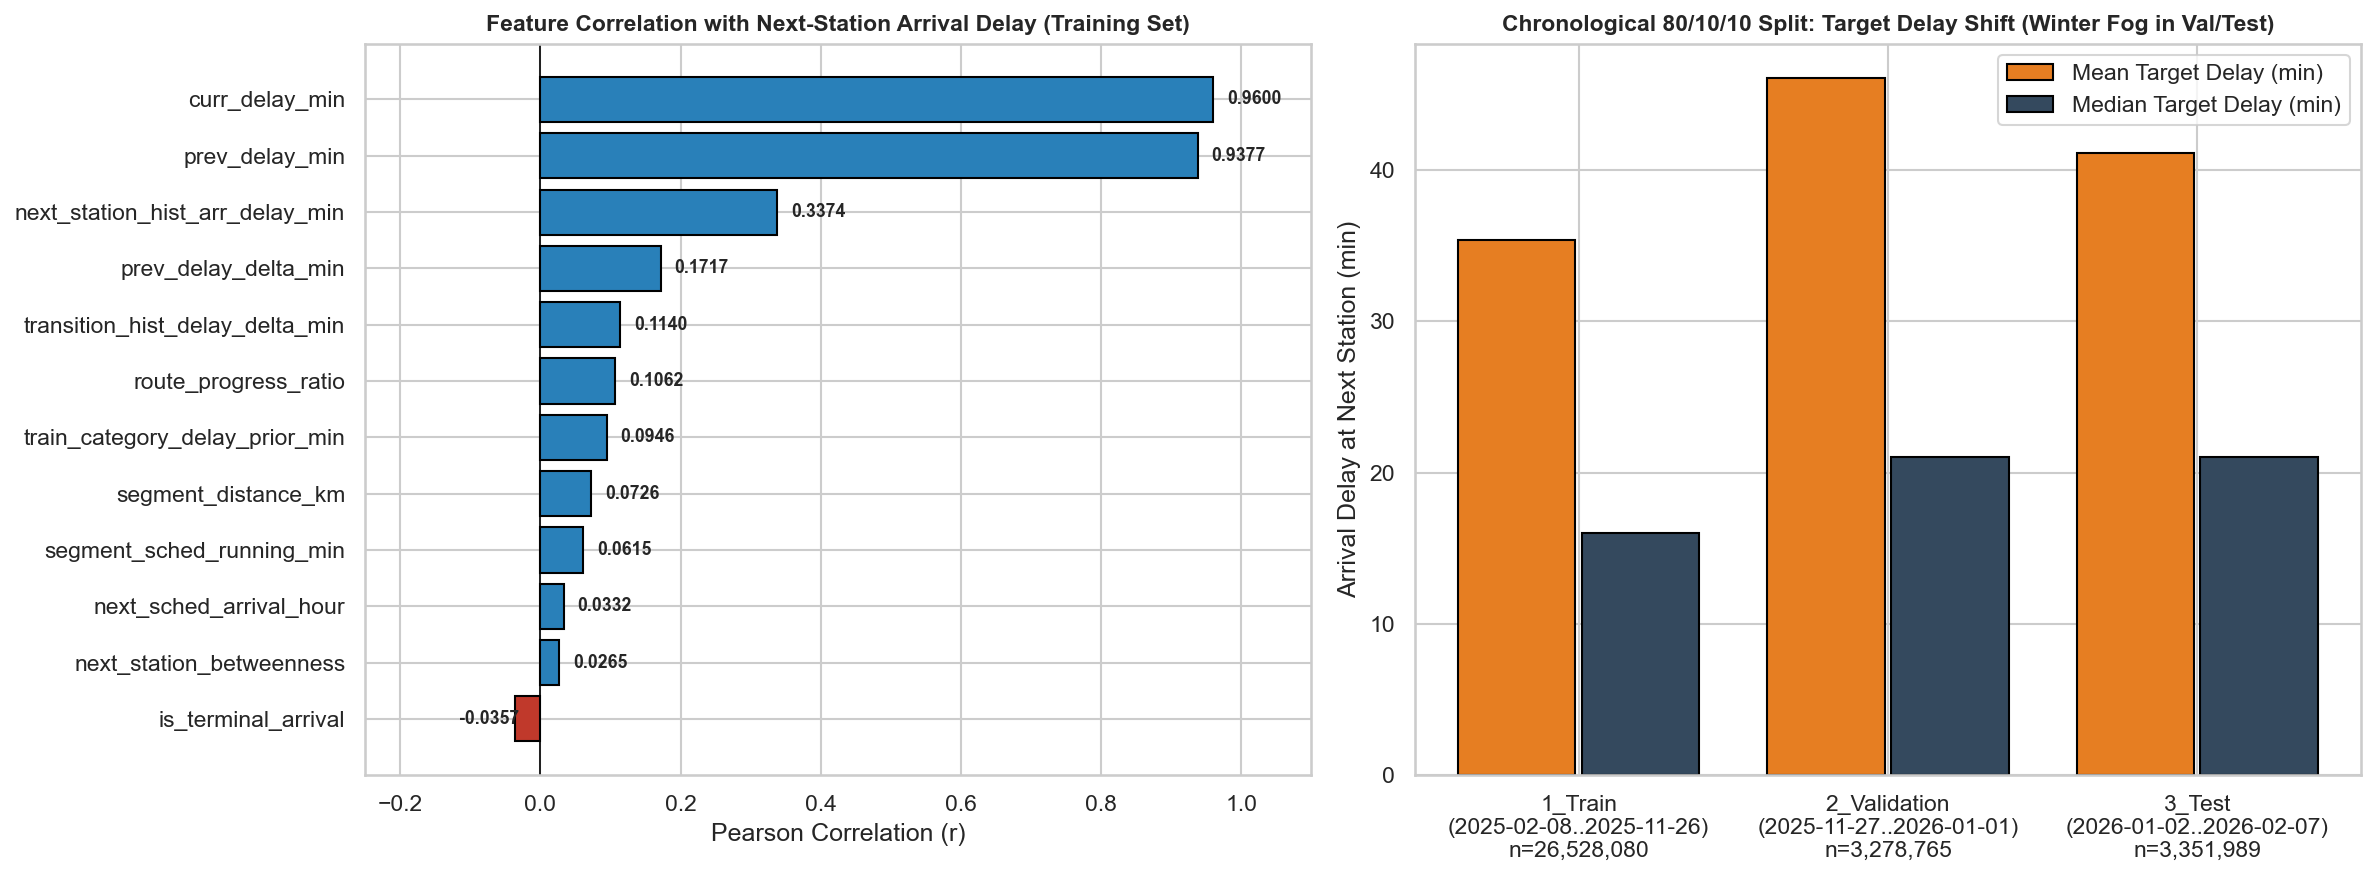

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Pearson Correlation of the 12 Engineered Features with Target (Training Set)
feat_corr_sorted = feature_metadata_df.sort_values("corr_with_target_train", ascending=True)
colors = ["#2980b9" if v >= 0 else "#c0392b" for v in feat_corr_sorted["corr_with_target_train"]]
axes[0].barh(feat_corr_sorted["feature_name"], feat_corr_sorted["corr_with_target_train"], color=colors, edgecolor="black")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Feature Correlation with Next-Station Arrival Delay (Training Set)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Pearson Correlation (r)")
for idx, row in enumerate(feat_corr_sorted.itertuples()):
    offset = 0.02 if row.corr_with_target_train >= 0 else -0.08
    axes[0].text(row.corr_with_target_train + offset, idx, f"{row.corr_with_target_train:.4f}", va="center", fontsize=8.5, fontweight="bold")
axes[0].set_xlim(-0.25, 1.10)

# Right plot: Chronological Target Delay Distribution Across Train / Validation / Test
x_pos = np.arange(len(split_summary_df))
axes[1].bar(x_pos - 0.2, split_summary_df["target_mean_delay_min"], width=0.38, label="Mean Target Delay (min)", color="#e67e22", edgecolor="black")
axes[1].bar(x_pos + 0.2, split_summary_df["target_median_delay_min"], width=0.38, label="Median Target Delay (min)", color="#34495e", edgecolor="black")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(
    [f"{r.partition_name}\n({r.min_date}..{r.max_date})\nn={r.n_transitions:,}" for r in split_summary_df.itertuples()]
)
axes[1].set_ylabel("Arrival Delay at Next Station (min)")
axes[1].set_title("Chronological 80/10/10 Split: Target Delay Shift (Winter Fog in Val/Test)", fontsize=11, fontweight="bold")
axes[1].legend()

plt.tight_layout()
fig_path = FIG_DIR / "step04_02_feature_correlations_and_split_distributions.png"
plt.savefig(fig_path, dpi=150)
plt.show()

In [7]:
findings_step04_02 = {
    "step": "step04_02_prediction_dataset",
    "prediction_objective": "Predict arrival delay (minutes) at the next scheduled station (sched_station_no = k + 1) using strictly prediction-time information at current station (k) and previous station (k - 1).",
    "n_features": len(FEATURE_COLS),
    "feature_columns": FEATURE_COLS,
    "target_column": TARGET_COL,
    "transition_eligibility_audit": transition_eligibility_audit.to_dict(orient="records"),
    "chronological_split_summary": split_summary_df.to_dict(orient="records"),
    "feature_statistics_and_correlations_train": feature_metadata_df.to_dict(orient="records"),
    "global_train_priors": global_train_priors.to_dict(orient="records")[0],
    "train_category_priors": train_cat_priors_df.to_dict(orient="records"),
    "saved_files": [
        "results/step04_02_train_features.parquet",
        "results/step04_02_val_features.parquet",
        "results/step04_02_test_features.parquet",
        "results/step04_02_preprocessing_artifacts.json",
        "results/step04_02_feature_engineering_metadata.csv",
        "results/step04_02_split_and_feature_metadata.csv",
        "results/figures/step04_02_feature_correlations_and_split_distributions.png",
    ],
}

findings_out_path = RESULT_DIR / "step04_02_PREDICTION_DATASET_FINDINGS.json"
with open(findings_out_path, "w", encoding="utf-8") as f:
    json.dump(findings_step04_02, f, indent=2)

print("=== STEP 4.2 VALIDATION & EXPORT COMPLETE ===")
print(f"Saved findings to: {findings_out_path}")

=== STEP 4.2 VALIDATION & EXPORT COMPLETE ===
Saved findings to: D:\M_Tech_CSE_AI\SEM01\DWDM\project\indian_railway_delay\results\step04_02_PREDICTION_DATASET_FINDINGS.json
